# Fase 1 por dentro: la atención y el GPT paso a paso

Este notebook construye la atención desde cero con matrices diminutas y luego usa el `model.py` real:

1. Mezclar información del pasado con una media.
2. Una cabeza de atención a mano: Q, K, V, máscara y softmax.
3. Por qué se divide por √d.
4. Multi-head: cómo se reparten las dimensiones.
5. El modelo completo: dónde están los parámetros.
6. Comprobar la causalidad.
7. Entrenar un GPT diminuto en CPU y compararlo con el bigrama.
8. Ver qué mira cada cabeza.

Requisito: `data/quijote/input.txt` (de `phases/0_bigram/prepare.py`). Todo corre en CPU en menos de un minuto.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Works whether the kernel starts in the repo root or in the phase folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())

sys.path.insert(0, str(ROOT / "phases" / "1_gpt"))
from data import CharTokenizer, get_batch, load_corpus, train_val_split
from model import GPT, CausalSelfAttention, GPTConfig

text = load_corpus()
tokenizer = CharTokenizer.from_text(text)
data = torch.tensor(tokenizer.encode(text))
splits = train_val_split(data)
V = tokenizer.vocab_size
print("vocab:", V, "| train:", len(splits["train"]), "| val:", len(splits["val"]))

vocab: 92 | train: 1899634 | val: 211071


## 1. El problema: mezclar información del pasado

En el bigrama, la posición `t` solo veía su propio carácter. Queremos que cada posición pueda **recoger información de todas las anteriores**, y nunca de las futuras.

La versión más tonta es la media de los vectores anteriores. Se hace con una sola multiplicación por una matriz triangular inferior normalizada:

In [2]:
torch.manual_seed(0)
T, C = 5, 2
x = torch.randn(T, C)  # 5 positions, each a 2-dimensional vector

w = torch.tril(torch.ones(T, T))
w = w / w.sum(dim=1, keepdim=True)  # row t averages positions 0..t
print("pesos:\n", w)
print("\nx:\n", x)
print("\nw @ x (media de lo anterior):\n", w @ x)

pesos:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])

x:
 tensor([[ 1.5410, -0.2934],
        [-2.1788,  0.5684],
        [-1.0845, -1.3986],
        [ 0.4033,  0.8380],
        [-0.7193, -0.4033]])

w @ x (media de lo anterior):
 tensor([[ 1.5410, -0.2934],
        [-0.3189,  0.1375],
        [-0.5741, -0.3745],
        [-0.3297, -0.0714],
        [-0.4076, -0.1378]])


La misma matriz sale de un **softmax** sobre puntuaciones a cero en las que el futuro se pone a `-inf` (`exp(-inf) = 0`). Este truco es el que usa la atención real.

In [3]:
scores = torch.zeros(T, T)
scores = scores.masked_fill(torch.tril(torch.ones(T, T)) == 0, float("-inf"))
print(scores)
print(F.softmax(scores, dim=-1))

tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000]])


La atención es exactamente esto, con una diferencia: las puntuaciones no son ceros, sino que **dependen de los datos**. Cada posición decide cuánto le interesa cada posición anterior.

## 2. Una cabeza de atención a mano

Cada posición produce tres vectores con tres matrices aprendidas:

- **query** (q): "qué estoy buscando".
- **key** (k): "qué contengo".
- **value** (v): "qué aporto si me eligen".

La puntuación de `t` hacia `s` es `q_t · k_s`: alta si lo que busca `t` encaja con lo que contiene `s`.

pesos de atención:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2100, 0.7900, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2300, 0.1200, 0.6500, 0.0000, 0.0000, 0.0000],
        [0.0300, 0.1500, 0.6100, 0.2100, 0.0000, 0.0000],
        [0.0400, 0.1300, 0.5000, 0.1100, 0.2100, 0.0000],
        [0.1900, 0.1300, 0.0400, 0.1700, 0.4300, 0.0300]])

cada fila suma: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
salida: (6, 8)


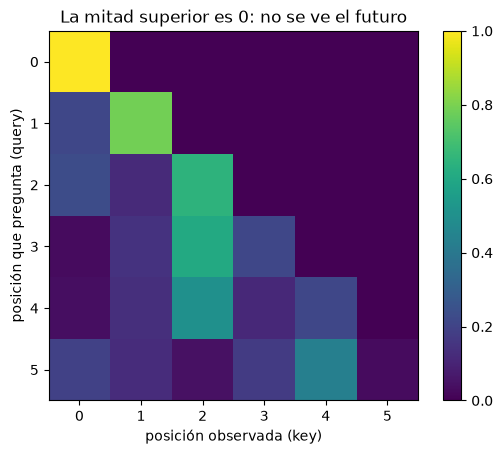

In [4]:
torch.manual_seed(1)
T, C, d = 6, 16, 8  # 6 positions, 16-dim embeddings, 8-dim head
x = torch.randn(T, C)
Wq, Wk, Wv = (torch.randn(C, d) / math.sqrt(C) for _ in range(3))

q, k, v = x @ Wq, x @ Wk, x @ Wv  # (T, d) each
scores = q @ k.T / math.sqrt(d)  # (T, T): every query against every key
mask = torch.tril(torch.ones(T, T, dtype=torch.bool))
weights = F.softmax(scores.masked_fill(~mask, float("-inf")), dim=-1)
out = weights @ v  # (T, d): weighted sum of the values

print("pesos de atención:\n", weights.round(decimals=2))
print("\ncada fila suma:", weights.sum(dim=-1))
print("salida:", tuple(out.shape))

plt.imshow(weights, cmap="viridis")
plt.xlabel("posición observada (key)")
plt.ylabel("posición que pregunta (query)")
plt.title("La mitad superior es 0: no se ve el futuro")
plt.colorbar()
plt.show()

## 3. ¿Por qué dividir por √d?

Si `q` y `k` tienen componentes de varianza 1, su producto escalar tiene varianza `d`. Con `d = 64` las puntuaciones son enormes, el softmax se vuelve casi *one-hot* y los gradientes de las demás posiciones desaparecen. Dividir por √d devuelve la varianza a 1.

In [5]:
for d in [8, 64, 512]:
    q, k = torch.randn(10_000, d), torch.randn(10_000, d)
    s = (q * k).sum(dim=-1)
    print(f"d={d:4d} | var(q·k) = {s.var():7.1f} | var(q·k / √d) = {(s / math.sqrt(d)).var():.2f}")

logits = torch.tensor([1.0, 2.0, 3.0])
print("\nsoftmax normal:     ", F.softmax(logits, dim=-1).numpy().round(3))
print("softmax ×8 (sin √d):", F.softmax(logits * 8, dim=-1).numpy().round(3))

d=   8 | var(q·k) =     7.9 | var(q·k / √d) = 0.99
d=  64 | var(q·k) =    64.6 | var(q·k / √d) = 1.01
d= 512 | var(q·k) =   518.1 | var(q·k / √d) = 1.01

softmax normal:      [0.09  0.245 0.665]
softmax ×8 (sin √d): [0. 0. 1.]


## 4. Multi-head: las mismas cuentas, en paralelo

Con `n_embd = 8` y `n_head = 2`, cada cabeza trabaja con 4 dimensiones. No se duplica nada: el vector se **trocea**, cada trozo hace su propia atención y al final se concatenan.

Reproducimos a mano el `forward` de `CausalSelfAttention` y comprobamos que da lo mismo que el módulo real:

In [6]:
torch.manual_seed(0)
cfg = GPTConfig(vocab_size=V, block_size=8, n_layer=1, n_head=2, n_embd=8, dropout=0.0)
attn = CausalSelfAttention(cfg).eval()
x = torch.randn(1, 6, 8)  # (batch, time, channels)

q, k, v = attn.qkv_proj(x).split(8, dim=2)
print("q tras la proyección:      ", tuple(q.shape), "(batch, time, channels)")
q = q.view(1, 6, 2, 4).transpose(1, 2)
k = k.view(1, 6, 2, 4).transpose(1, 2)
v = v.view(1, 6, 2, 4).transpose(1, 2)
print("q repartido en cabezas:    ", tuple(q.shape), "(batch, head, time, head_dim)")

scores = q @ k.transpose(-2, -1) / math.sqrt(4)
print("puntuaciones:              ", tuple(scores.shape), "(batch, head, time, time)")
scores = scores.masked_fill(~torch.tril(torch.ones(6, 6, dtype=torch.bool)), float("-inf"))
y = F.softmax(scores, dim=-1) @ v
y = y.transpose(1, 2).reshape(1, 6, 8)  # concatenate heads
print("cabezas concatenadas:      ", tuple(y.shape))
y = attn.out_proj(y)

print("\n¿Igual que el módulo?", torch.allclose(y, attn(x), atol=1e-6))

q tras la proyección:       (1, 6, 8) (batch, time, channels)
q repartido en cabezas:     (1, 2, 6, 4) (batch, head, time, head_dim)
puntuaciones:               (1, 2, 6, 6) (batch, head, time, time)
cabezas concatenadas:       (1, 6, 8)

¿Igual que el módulo? True


## 5. El modelo completo: dónde están los parámetros

Un bloque es `x + atención(LayerNorm(x))` y luego `x + MLP(LayerNorm(x))`. La configuración por defecto de `train.py` apila 6 bloques. Contamos los parámetros por componente:

In [7]:
model = GPT(GPTConfig(vocab_size=V))
groups = {}
for name, p in model.named_parameters():  # lm_head is tied to token_embedding: counted once
    key = name.split(".")[0] if not name.startswith("blocks") else "blocks.*." + name.split(".")[2]
    groups[key] = groups.get(key, 0) + p.numel()
for key, n in groups.items():
    print(f"{key:22s} {n:>10,}")
print(f"{'TOTAL':22s} {model.num_params():>10,}")

C = model.config.n_embd
print(f"\nPor bloque: atención ≈ 4·C² = {4 * C * C:,} | MLP ≈ 8·C² = {8 * C * C:,} (C = {C})")

token_embedding            35,328
position_embedding         98,304
blocks.*.ln_1               4,608
blocks.*.attn           3,548,160
blocks.*.ln_2               4,608
blocks.*.mlp            7,089,408
ln_f                          768
TOTAL                  10,781,184

Por bloque: atención ≈ 4·C² = 589,824 | MLP ≈ 8·C² = 1,179,648 (C = 384)


El MLP tiene el doble de parámetros que la atención. Casi todo el modelo está en los bloques; el embedding de caracteres es diminuto (V = 92). En la fase 2, con 16k tokens, el embedding pasará a pesar mucho más.

## 6. Causalidad: el futuro no puede influir en el pasado

Si se cambian los tokens a partir de la posición 10, los logits de las posiciones 0–9 deben quedar **idénticos**. Es lo que comprueba `test_causality`, y la condición para que entrenar con todas las posiciones a la vez no sea hacer trampa.

In [8]:
torch.manual_seed(0)
small = GPT(GPTConfig(vocab_size=V, block_size=32, n_layer=2, n_head=2, n_embd=32, dropout=0.0)).eval()
a = torch.randint(V, (1, 16))
b = a.clone()
b[0, 10:] = torch.randint(V, (6,))
with torch.no_grad():
    diff = (small(a)[0] - small(b)[0]).abs().amax(dim=-1)[0]
print("diferencia máxima de logits por posición:")
print(diff.numpy().round(4))

diferencia máxima de logits por posición:
[0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.7243 0.46   0.3593 0.4876 0.5578 0.3031]


## 7. Entrenar un GPT diminuto en CPU

2 capas, 4 cabezas, 64 dimensiones y 64 de contexto: ~110k parámetros, unos 30 segundos de CPU. Usa el mismo `lr_at` (warmup + coseno) y el mismo `configure_optimizer` que `train.py`.

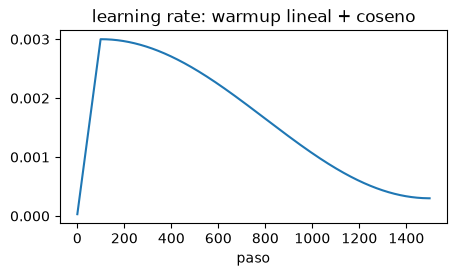

In [9]:
from types import SimpleNamespace

from train import lr_at

hp = SimpleNamespace(lr=3e-3, min_lr=3e-4, warmup_steps=100, max_steps=1500)
plt.figure(figsize=(5, 2.5))
plt.plot([lr_at(s, hp) for s in range(hp.max_steps)])
plt.title("learning rate: warmup lineal + coseno")
plt.xlabel("paso")
plt.show()

parámetros: 110,080


19s
val: 1.6899 nats = 2.438 bits/char (bigrama: 2.3047 = 3.325 bits/char)


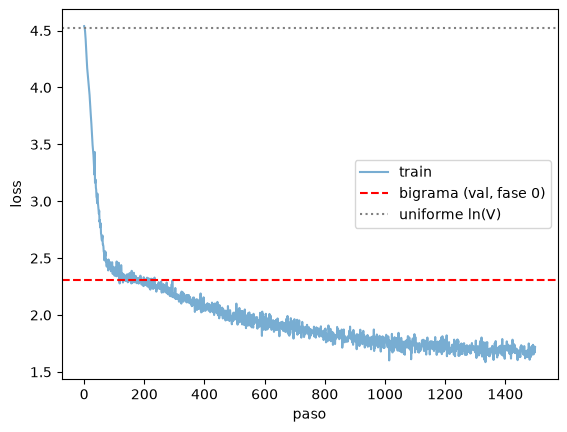

In [10]:
import time

torch.manual_seed(1337)
cfg = GPTConfig(vocab_size=V, block_size=64, n_layer=2, n_head=4, n_embd=64, dropout=0.0)
tiny = GPT(cfg)
optimizer = tiny.configure_optimizer(hp.lr, 0.1, (0.9, 0.95), "cpu")
print(f"parámetros: {tiny.num_params():,}")

start, curve = time.perf_counter(), []
for step in range(hp.max_steps):
    for group in optimizer.param_groups:
        group["lr"] = lr_at(step, hp)
    x, y = get_batch(splits["train"], 32, cfg.block_size)
    _, loss = tiny(x, y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(tiny.parameters(), 1.0)
    optimizer.step()
    curve.append(loss.item())
print(f"{time.perf_counter() - start:.0f}s")

tiny.eval()
with torch.no_grad():
    val_losses = [tiny(*get_batch(splits["val"], 64, cfg.block_size))[1].item() for _ in range(20)]
tiny_val = sum(val_losses) / len(val_losses)
print(f"val: {tiny_val:.4f} nats = {tiny_val / math.log(2):.3f} bits/char (bigrama: 2.3047 = 3.325 bits/char)")

plt.plot(curve, alpha=0.6, label="train")
plt.axhline(2.3047, color="red", linestyle="--", label="bigrama (val, fase 0)")
plt.axhline(math.log(V), color="gray", linestyle=":", label="uniforme ln(V)")
plt.xlabel("paso")
plt.ylabel("loss")
plt.legend()
plt.show()

Incluso este modelo diminuto baja claramente del bigrama: el contexto empieza a pagar. El modelo de `train.py` (10,7M de parámetros, 256 de contexto) baja mucho más.

## 8. Qué mira cada cabeza

Recalculamos los pesos de atención del modelo entrenado sobre el prompt fijo. Cada mapa es una cabeza. Suelen aparecer patrones como "mira al carácter anterior" (la diagonal justo bajo la principal) o "mira al último espacio" (el inicio de la palabra actual).

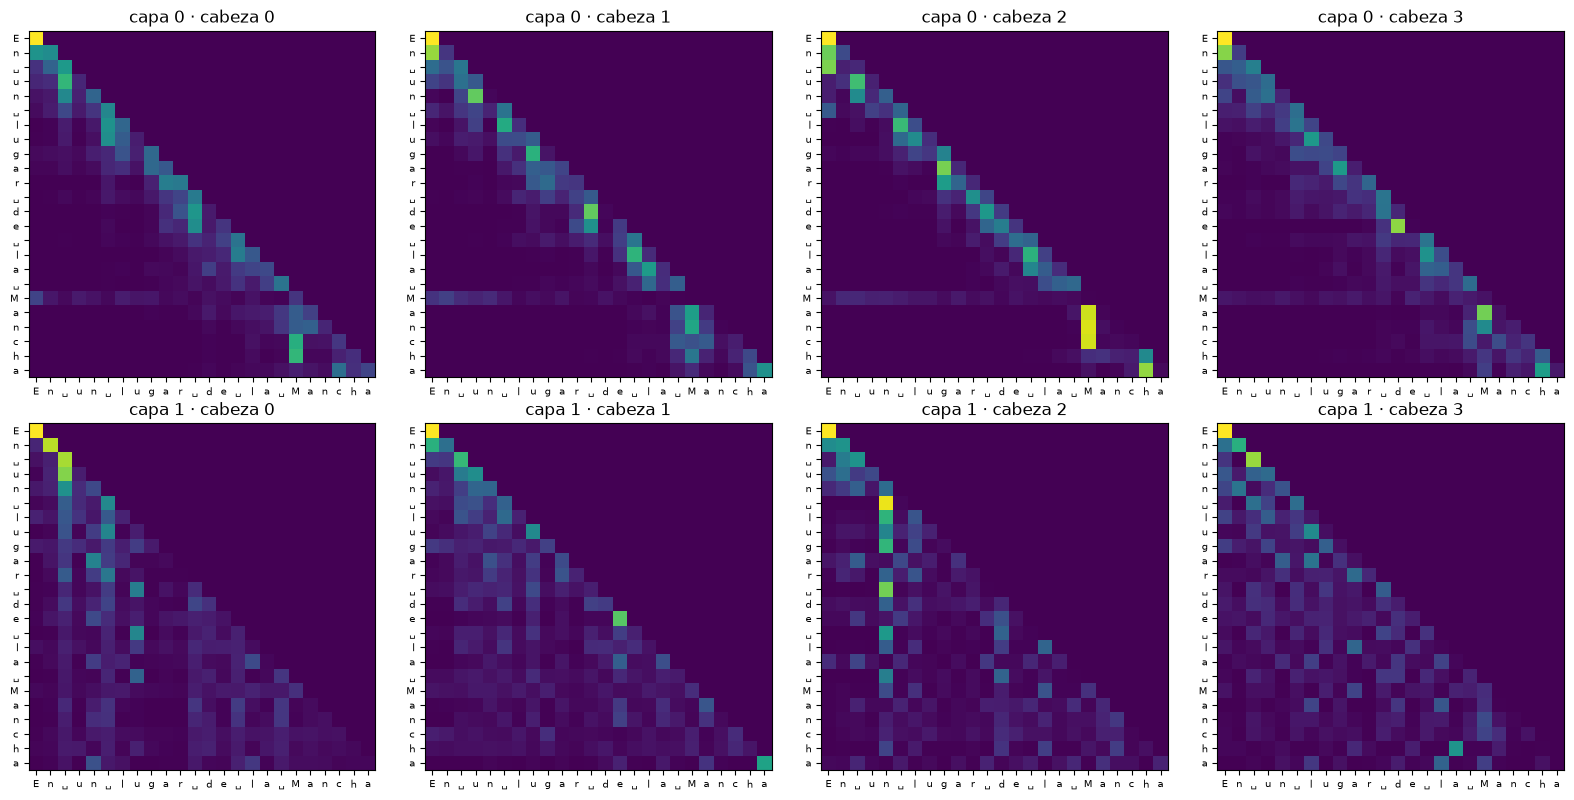

In [11]:
@torch.no_grad()
def attention_maps(model, idx):
    """Recompute each layer's attention weights, as CausalSelfAttention.forward does."""
    T = idx.size(1)
    x = model.token_embedding(idx) + model.position_embedding(torch.arange(T))
    maps = []
    for block in model.blocks:
        a = block.attn
        q, k, _ = a.qkv_proj(block.ln_1(x)).split(model.config.n_embd, dim=2)
        q = q.view(1, T, a.n_head, a.head_dim).transpose(1, 2)
        k = k.view(1, T, a.n_head, a.head_dim).transpose(1, 2)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(a.head_dim)
        scores = scores.masked_fill(~a.causal_mask[:, :, :T, :T], float("-inf"))
        maps.append(F.softmax(scores, dim=-1)[0])
        x = block(x)
    return maps


prompt = "En un lugar de la Mancha"
idx = torch.tensor([tokenizer.encode(prompt)])
maps = attention_maps(tiny, idx)
labels = ["␣" if c == " " else c for c in prompt]

fig, axes = plt.subplots(len(maps), cfg.n_head, figsize=(4 * cfg.n_head, 4 * len(maps)))
for layer, layer_maps in enumerate(maps):
    for head in range(cfg.n_head):
        ax = axes[layer, head]
        ax.imshow(layer_maps[head], cmap="viridis")
        ax.set_xticks(range(len(prompt)), labels, fontsize=7)
        ax.set_yticks(range(len(prompt)), labels, fontsize=7)
        ax.set_title(f"capa {layer} · cabeza {head}")
plt.tight_layout()
plt.show()

## 9. Generar con top-k

`generate` repite: logits de la última posición → temperatura → quedarse con los `k` más probables → muestrear. Comparado con la fase 0, ya salen palabras reales.

In [12]:
torch.manual_seed(0)
out = tiny.generate(idx, max_new_tokens=200, temperature=0.8, top_k=20)
print(tokenizer.decode(out[0].tolist()))

En un lugar de la Manchambó de una se aquellas que ay que la la vastarmos, que diero
la manero estigo ya destiguna del ventero estabarso, así al marios al aben
aquel del hel fració la quere parevir darde que no el duro cabra


## Conclusión

La atención es una media ponderada cuyos pesos calcula el propio modelo a partir de los datos. Todo lo demás (multi-head, MLP, residuales, LayerNorm) sirve para poder apilar muchas capas y entrenarlas de forma estable.

El siguiente cuello de botella es el **tokenizer**: con caracteres, 256 posiciones de contexto son solo ~45 palabras. La fase 2 lo resuelve con BPE.